# EDA: 2011 U.S. Debt Ceiling Crisis & Credit Downgrade

**Owner:** Salah · **Week 1** · Market Stress Early-Warning System

**Goal:** understand what U.S. equity market stress looked like in 2011 during the debt ceiling standoff and S&P credit downgrade, check data quality/survivorship for this period, and examine whether network co-movement rose before the worst of the stress or only during it.

**Before running:** run `python scripts/download_sp500_prices.py` from the repo root. This notebook reads `data/processed/`. If `data/processed/daily_panel.parquet` from `01_data_collection.ipynb` exists, the FRED stress index is added to the plots.

**Window:** 2011-01-01 to 2011-12-31, with 2010 loaded as warm-up for rolling windows.

Reference dates used for chart markers:

| Date | Event |
|---|---|
| 2011-07-22 | Debt Ceiling Standoff Peak |
| 2011-08-05 | S&P U.S. Credit Downgrade (AAA to AA+) |
| 2011-08-08 | Black Monday (Global Selloff) |

In [9]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import prices as px
import data_loading as dl

PROC = ROOT / "data" / "processed"
WARMUP, START, END = "2010-01-01", "2011-01-01", "2011-12-31"

EVENTS_2011 = {
    "2011-07-22": "Debt Ceiling Peak",
    "2011-08-05": "S&P Downgrade",
    "2011-08-08": "Black Monday",
}

def mark_events(ax, labels=True):
    for d, lab in EVENTS_2011.items():
        ax.axvline(pd.Timestamp(d), color="grey", ls="--", lw=0.8)
        if labels:
            ax.text(pd.Timestamp(d), 1.0, f" {lab}", transform=ax.get_xaxis_transform(),
                    rotation=90, va="top", ha="left", fontsize=8, color="grey")

pd.set_option("display.width", 140)

## 1. Load data

In [10]:
close = pd.read_parquet(PROC / "sp500_close.parquet").loc[WARMUP:END]
membership = pd.read_parquet(PROC / "sp500_membership.parquet").loc[WARMUP:END]

stock_cols = membership.columns
rets_all = close.reindex(columns=stock_cols).pct_change(fill_method=None)
rets = rets_all.where(membership)

gspc = close["^GSPC"]
print(f"{close.index.min().date()} to {close.index.max().date()}: {len(close)} trading days")
print(f"{len(stock_cols)} tickers were members at some point in the download period")

2010-01-04 to 2011-12-30: 504 trading days
977 tickers were members at some point in the download period


## 2. Data quality: how much of the index do we actually see?

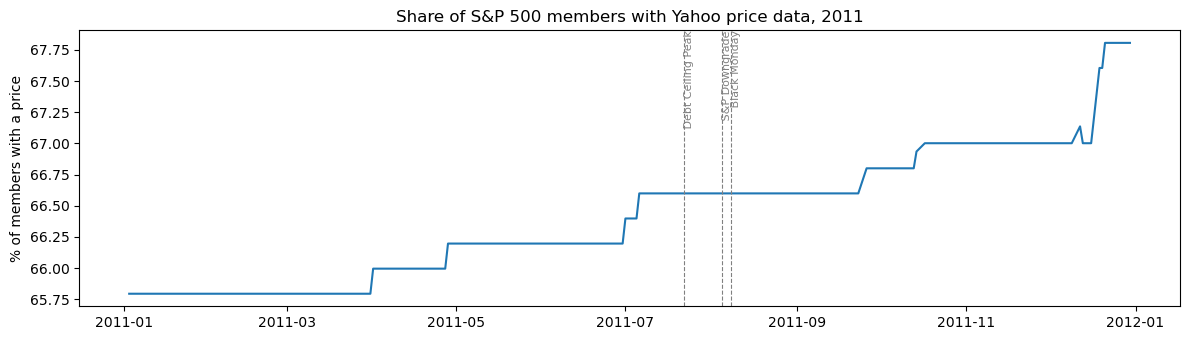

Average share priced, full window: 66.4%
Lowest daily share: 65.8% on 2011-01-03


In [11]:
cov = px.coverage_by_day(close, membership).loc[START:END]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(cov.index, cov["share_priced"] * 100)
ax.set_ylabel("% of members with a price")
ax.set_title("Share of S&P 500 members with Yahoo price data, 2011")
mark_events(ax)
plt.tight_layout(); plt.show()

print(f"Average share priced, full window: {cov['share_priced'].mean():.1%}")
print(f"Lowest daily share: {cov['share_priced'].min():.1%} on {cov['share_priced'].idxmin().date()}")

## 3. Market overview: level, drawdown and volatility

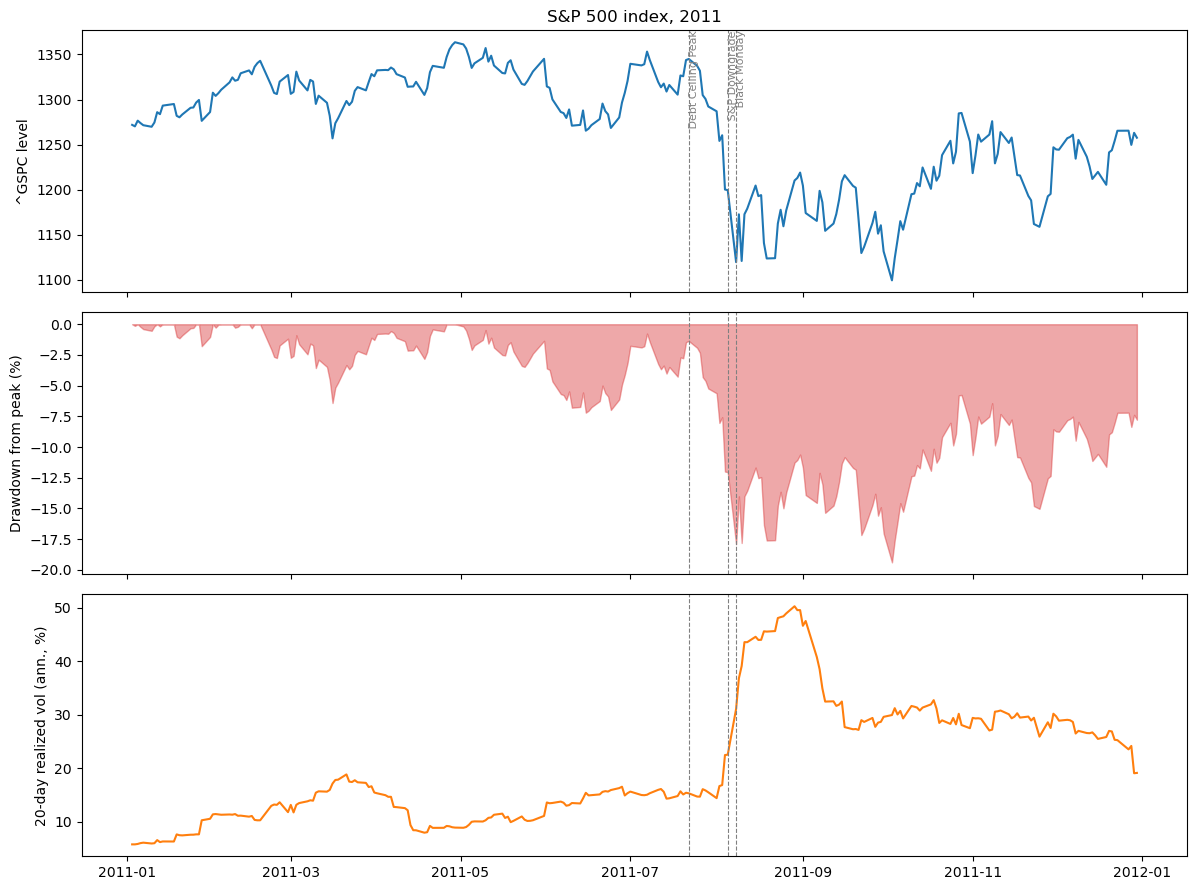

Maximum drawdown in 2011: -19.4%
Highest 20-day realized vol: 50.3% on 2011-08-29


In [12]:
g = gspc.loc[START:END]
drawdown = g / g.cummax() - 1
vol20 = gspc.pct_change(fill_method=None).rolling(20).std().loc[START:END] * np.sqrt(252)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(g.index, g); axes[0].set_ylabel("^GSPC level")
axes[1].fill_between(drawdown.index, drawdown * 100, 0, color="tab:red", alpha=0.4)
axes[1].set_ylabel("Drawdown from peak (%)")
axes[2].plot(vol20.index, vol20 * 100, color="tab:orange"); axes[2].set_ylabel("20-day realized vol (ann., %)")
for i, ax in enumerate(axes):
    mark_events(ax, labels=(i == 0))
axes[0].set_title("S&P 500 index, 2011")
plt.tight_layout(); plt.show()

print(f"Maximum drawdown in 2011: {drawdown.min():.1%}")
print(f"Highest 20-day realized vol: {vol20.max():.1%} on {vol20.idxmax().date()}")

## 4. Cross-section: dispersion and breadth

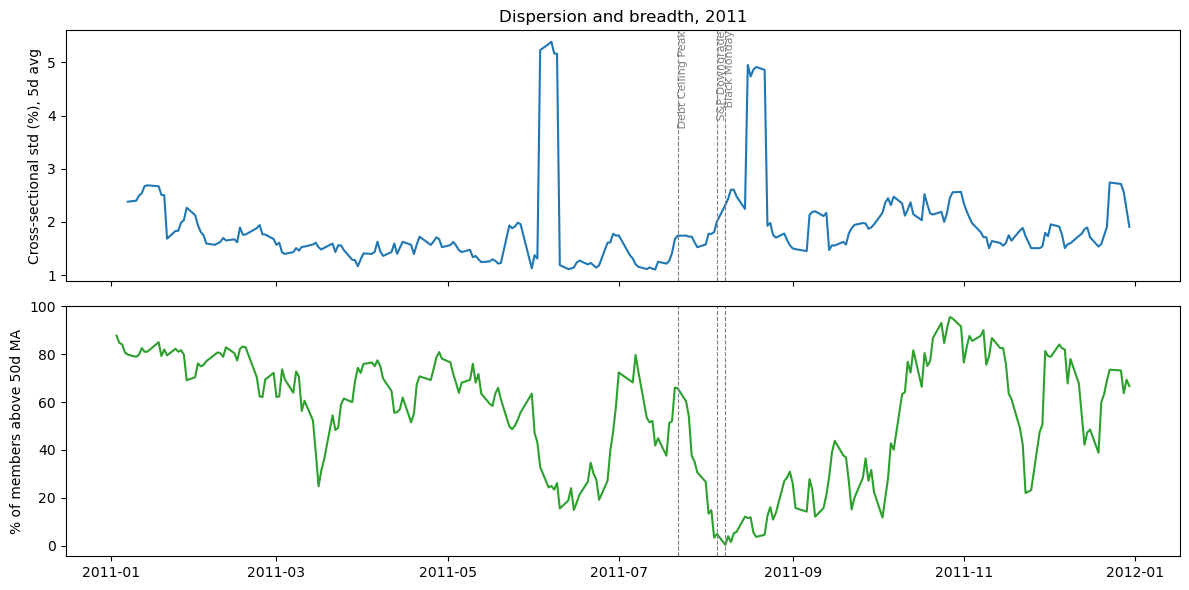

In [13]:
dispersion = rets.loc[START:END].std(axis=1, skipna=True)
ma50 = close.reindex(columns=stock_cols).rolling(50, min_periods=50).mean()
above = (close.reindex(columns=stock_cols) > ma50).where(membership & ma50.notna())
breadth = above.mean(axis=1, skipna=True).loc[START:END]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(dispersion.index, dispersion.rolling(5).mean() * 100)
axes[0].set_ylabel("Cross-sectional std (%), 5d avg")
axes[1].plot(breadth.index, breadth * 100, color="tab:green")
axes[1].set_ylabel("% of members above 50d MA")
for i, ax in enumerate(axes):
    mark_events(ax, labels=(i == 0))
axes[0].set_title("Dispersion and breadth, 2011")
plt.tight_layout(); plt.show()

## 5. Connectedness: did stocks move together during the debt ceiling crisis?

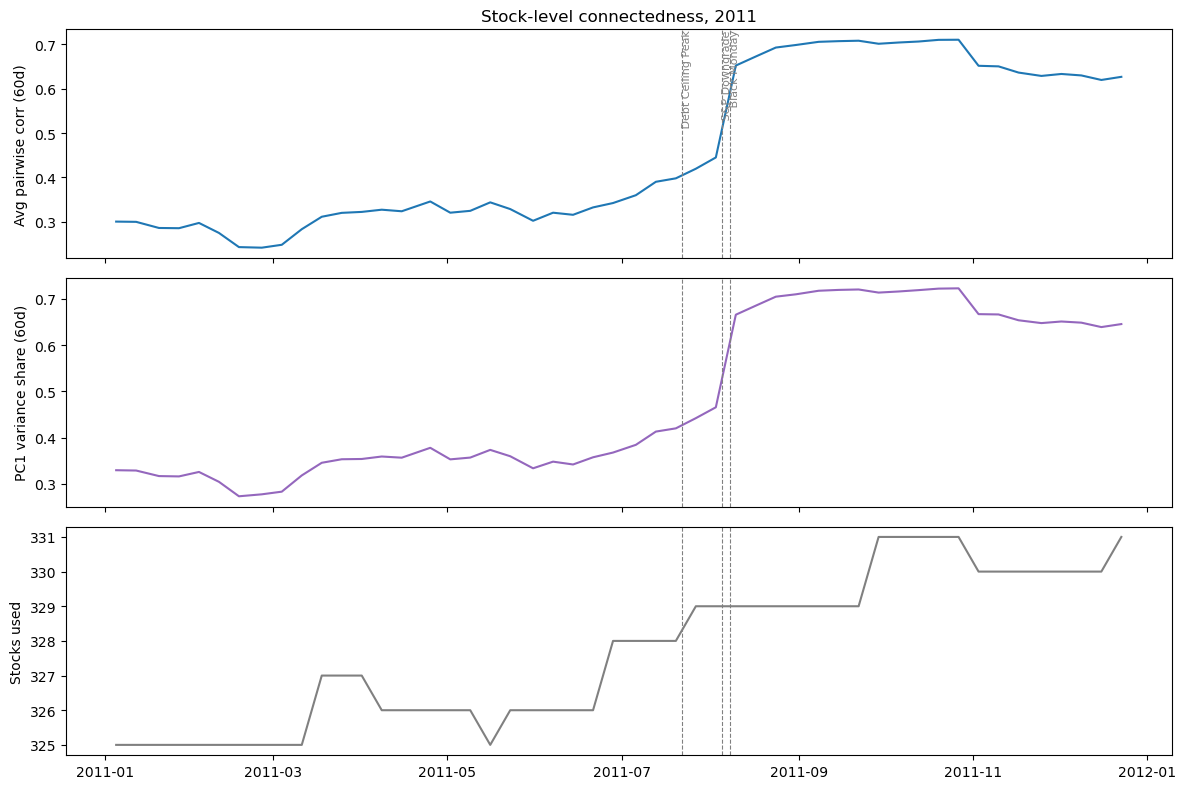

In [14]:
def connectedness(returns: pd.DataFrame, window: int = 60, step: int = 5, min_stocks: int = 100) -> pd.DataFrame:
    rows = {}
    idx = returns.index
    for end in range(window, len(idx) + 1, step):
        block = returns.iloc[end - window:end]
        block = block.loc[:, block.notna().all()]
        block = block.loc[:, block.std() > 0]
        n = block.shape[1]
        if n < min_stocks:
            continue
        c = np.corrcoef(block.values, rowvar=False)
        avg = (c.sum() - n) / (n * (n - 1))
        top = np.linalg.eigvalsh(c)[-1] / n
        rows[idx[end - 1]] = {"avg_corr": avg, "pc1_share": top, "n_stocks": n}
    return pd.DataFrame(rows).T

conn = connectedness(rets.loc[WARMUP:END]).loc[START:END]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(conn.index, conn["avg_corr"]); axes[0].set_ylabel("Avg pairwise corr (60d)")
axes[1].plot(conn.index, conn["pc1_share"], color="tab:purple"); axes[1].set_ylabel("PC1 variance share (60d)")
axes[2].plot(conn.index, conn["n_stocks"], color="grey"); axes[2].set_ylabel("Stocks used")
for i, ax in enumerate(axes):
    mark_events(ax, labels=(i == 0))
axes[0].set_title("Stock-level connectedness, 2011")
plt.tight_layout(); plt.show()

## 6. Observations (2011 Debt Ceiling Crisis)

1. **VIX and Volatility:** Note how sharply the VIX spiked past 40 in early August 2011 following the U.S. debt downgrade.
2. **Drawdown:** The S&P 500 experienced a swift correction exceeding 15% during the summer standoff.
3. **Connectedness:** Average pairwise correlations spiked significantly as systemic panic caused asset classes to move together.
4. **Implications:** The 2011 episode serves as a powerful test case for non-financial systemic shocks (fiscal/sovereign risk rather than banking insolvency).